<a href="https://colab.research.google.com/github/Sara200413/TP3-vision-par-ordinateur/blob/main/TP3_Vision_par_ordinateur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Installation et imports

In [ ]:
# --- Installation
# opencv / numpy / matplotlib sont normalement déjà présents sur Colab, on les met par sécurité
!pip install -q opencv-python numpy matplotlib

# dlib-bin = dlib déjà compilé : l'installation prend quelques secondes
# (pip install dlib compile tout le C++ et peut durer plus de 10 minutes)
!pip install -q dlib-bin

# --no-deps : évite que pip essaie de réinstaller/compiler "dlib" normal
!pip install -q face_recognition --no-deps
# les autres dépendances de face_recognition (modèles pré-entraînés, etc.)
!pip install -q face_recognition_models Click Pillow "setuptools<81"

# YOLO (Partie 5)
!pip install -q ultralytics

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# --- Imports communs à tout le TP ---
import os
import time
import cv2                                   # OpenCV : lecture / traitement d'images et vidéos
import numpy as np                           # une image OpenCV est un tableau numpy
import matplotlib.pyplot as plt
from google.colab import files               # pour importer des fichiers dans Colab
from google.colab.patches import cv2_imshow  # cv2.imshow() plante sur Colab -> on utilise cette version

print("OpenCV :", cv2.__version__)

OpenCV : 4.14.0


In [ ]:

# Sélectionner d'un coup : image1.jpg, image_objects.jpg, people.jpg, ref.jpg, test.jpg
uploaded = files.upload()

attendus = ["image1.jpg", "image_objects.jpg", "people.jpg", "ref.jpg", "test.jpg"]
for nom in attendus:
    print(("OK       " if os.path.exists(nom) else "MANQUANT ") + nom)

Saving test.jpg to test.jpg
Saving ref.jpg to ref.jpg
Saving people.jpg to people.jpg
Saving image_objects.jpg to image_objects.jpg
Saving image1.jpg to image1.jpg
OK       image1.jpg
OK       image_objects.jpg
OK       people.jpg
OK       ref.jpg
OK       test.jpg


## Partie 1 : Concepts de base de la vision par ordinateur
### Exercice 1 : Analyse d'une image
Étapes : lire l'image → l'afficher → la passer en niveaux de gris → détecter les contours avec Canny.

Type        : <class 'numpy.ndarray'>
Dimensions  : (220, 220, 3) -> (hauteur, largeur, canaux)
Type pixels : uint8 -> entiers de 0 à 255


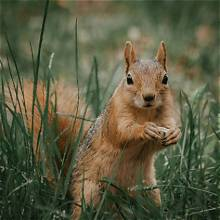

In [ ]:
# 1) Lecture : cv2.imread charge l'image en tableau numpy (hauteur x largeur x 3 canaux)
#    ATTENTION : OpenCV stocke les couleurs en BGR (Bleu, Vert, Rouge) et pas en RGB
img = cv2.imread("image1.jpg")
assert img is not None, "image1.jpg introuvable : vérifier le nom / l'upload"

print("Type        :", type(img))
print("Dimensions  :", img.shape, "-> (hauteur, largeur, canaux)")
print("Type pixels :", img.dtype, "-> entiers de 0 à 255")

# 2) Affichage : sur Colab on utilise cv2_imshow à la place de cv2.imshow + waitKey
cv2_imshow(img)

Dimensions gris : (220, 220) -> plus de canal de couleur


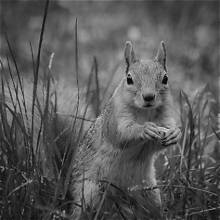

In [ ]:
# 3) Niveaux de gris : 3 canaux (B,G,R) -> 1 seul canal (intensité lumineuse)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Dimensions gris :", gray.shape, "-> plus de canal de couleur")
cv2_imshow(gray)

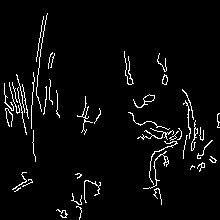

Pixels de contour AVEC flou : 1899
Pixels de contour SANS flou : 7074


In [ ]:
# 4) Détection de contours avec Canny
#    Canny cherche les endroits où l'intensité change brusquement (= les bords des objets).
#    Les deux nombres sont les seuils : 100 (bas) et 200 (haut)
#      - gradient > 200 : contour sûr
#      - gradient < 100 : ignoré
#      - entre les deux : gardé seulement s'il touche un contour sûr
#    Ici on applique Canny sur l'image en gris + floutée : c'est plus propre que sur l'image couleur
blur = cv2.GaussianBlur(gray, (5, 5), 0)   # flou gaussien : noyau 5x5, sigma calculé automatiquement (0)
edges = cv2.Canny(blur, 100, 200)
cv2_imshow(edges)

# Pour comparer avec la version du sujet (Canny directement sur l'image couleur) :
edges_sans_flou = cv2.Canny(gray, 100, 200)
print("Pixels de contour AVEC flou :", int(np.count_nonzero(edges)))
print("Pixels de contour SANS flou :", int(np.count_nonzero(edges_sans_flou)))

### Questions : réponses

**1. Que représente la matrice retournée par OpenCV pour l'image ?**
C'est un tableau numpy de forme `(hauteur, largeur, 3)`. Chaque case est un pixel et contient 3 valeurs entre 0 et 255 : l'intensité de **Bleu, Vert, Rouge** (ordre BGR, pas RGB). Une image en niveaux de gris est une matrice 2D `(hauteur, largeur)` où chaque valeur est une luminosité (0 = noir, 255 = blanc).

**2. Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?**
- On passe de 3 canaux à 1 : **3 fois moins de données**, donc des calculs plus rapides.
- Pour beaucoup de tâches (contours, détection de visages avec dlib), l'information importante est la **forme / le contraste**, pas la couleur.
- Les algorithmes comme Canny travaillent sur les variations d'intensité, donc un seul canal suffit.
- Cela rend le traitement moins sensible aux variations de couleur.

**3. Que peut nous apporter le filtre Gaussien ?** (`cv2.GaussianBlur(gray, (5, 5), 0)`)
Il **lisse l'image** : chaque pixel devient une moyenne pondérée de ses voisins (les plus proches comptent plus). Il **réduit le bruit** (petits grains, artefacts de compression), ce qui évite que Canny détecte de **faux contours**. Contrepartie : plus le noyau est grand, plus l'image est floue et les vrais contours fins sont atténués. C'est pourquoi on le met **avant** Canny dans la chaîne de prétraitement.

## Partie 2 : Traitement d'images et vidéos avec OpenCV
### Exercice 2 : Lecture vidéo / webcam
**Important :** `cv2.VideoCapture(0)` (webcam) **ne marche pas sur Colab**, car le code tourne sur un serveur distant sans caméra. Donc :
- on écrit une fonction qui marche avec **un fichier vidéo** (utilisable sur Colab) ;
- le code **webcam** pour un PC local est donné plus bas (à lancer dans VS Code / Jupyter local).

Pas de vidéo importée -> vidéo de démonstration créée à partir de image1.jpg
60 images traitées à 20.0 fps -> sortie_gris.mp4


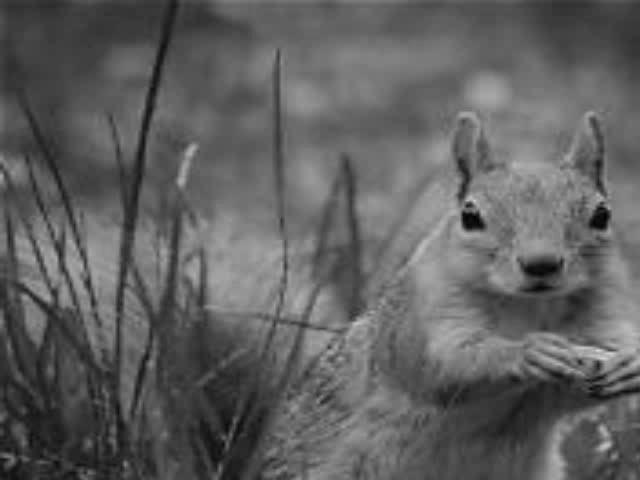

In [ ]:
def traiter_video(source, sortie="sortie_gris.mp4", max_frames=None):
    """Lit une vidéo image par image, la convertit en gris et enregistre le résultat."""
    cap = cv2.VideoCapture(source)           # source = chemin de fichier (ou 0 pour la webcam en local)
    if not cap.isOpened():
        raise IOError(f"Impossible d'ouvrir {source}")

    # On récupère les propriétés de la vidéo d'entrée pour créer une sortie identique
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 20.0  # certaines webcams renvoient 0 -> valeur par défaut
    fourcc = cv2.VideoWriter_fourcc(*'mp4v') # codec de compression
    # isColor=False : on écrit des images à 1 canal (gris)
    out = cv2.VideoWriter(sortie, fourcc, fps, (w, h), isColor=False)

    n = 0
    premiere = None
    while True:
        ret, frame = cap.read()              # ret = True si une image a bien été lue
        if not ret:                          # fin de la vidéo (ou erreur) -> on sort de la boucle
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)   # filtre appliqué à CHAQUE image
        out.write(gray)
        if premiere is None:
            premiere = gray
        n += 1
        if max_frames and n >= max_frames:
            break

    cap.release()                            # libère la caméra / le fichier
    out.release()                            # finalise le fichier de sortie
    return n, fps, premiere


def creer_video_demo(image_path, chemin="video_demo.mp4", n=60):
    """Fabrique une petite vidéo de test en 'balayant' une image (si on n'a pas de vidéo)."""
    base = cv2.resize(cv2.imread(image_path), (800, 600))
    w, h = 640, 480
    out = cv2.VideoWriter(chemin, cv2.VideoWriter_fourcc(*'mp4v'), 20.0, (w, h))
    for i in range(n):
        x = int(i * (800 - w) / (n - 1))
        y = int(i * (600 - h) / (n - 1))
        out.write(np.ascontiguousarray(base[y:y + h, x:x + w]))
    out.release()
    return chemin


# Si tu as une vraie vidéo, uploade-la et mets son nom ici (ex: "ma_video.mp4")
VIDEO = "ma_video.mp4"
if not os.path.exists(VIDEO):
    print("Pas de vidéo importée -> vidéo de démonstration créée à partir de image1.jpg")
    VIDEO = creer_video_demo("image1.jpg")

n, fps, premiere = traiter_video(VIDEO)
print(f"{n} images traitées à {fps:.1f} fps -> sortie_gris.mp4")
cv2_imshow(premiere)   # aperçu de la 1ère image en gris


import cv2

cap = cv2.VideoCapture(0)               # 0 = webcam par défaut (essayer 1 si ça ne marche pas)
while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)   # filtre gris en temps réel
    cv2.imshow('Webcam gris', gray)
    # waitKey(1) attend 1 ms une touche ; & 0xFF garde les 8 bits utiles ; ord('q') = code de la touche q
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
cap.release()
cv2.destroyAllWindows()
```

### Question : que se passe-t-il si on utilise une vidéo enregistrée à la place de la webcam ?
- On remplace `VideoCapture(0)` par `VideoCapture("fichier.mp4")` : le reste du code ne change pas.
- La vidéo a une **fin** : quand toutes les images sont lues, `cap.read()` renvoie `ret = False` et la boucle s'arrête d'elle-même (avec la webcam, ça ne s'arrête jamais tant qu'on n'appuie pas sur `q`).
- Le nombre d'images par seconde (fps) vient du fichier. En affichage local, `waitKey(1)` lit aussi vite que possible : pour respecter la vitesse réelle il faudrait `waitKey(int(1000/fps))`.
- Le traitement est **reproductible** (même vidéo = même résultat), ce qui est pratique pour tester.

## Partie 3 : Détection et segmentation d'objets avec Detectron2
### Exercice 3 : Détection d'objets (Mask R-CNN)

**Idée :**
- *Détection* = trouver les objets + leur boîte englobante + leur classe.
- *Segmentation d'instance* = en plus, un **masque pixel par pixel** pour **chaque** objet (deux personnes = deux masques différents).
- Mask R-CNN fait les deux. Le modèle est **pré-entraîné sur COCO** (80 classes : personne, voiture, chat, cravate...), donc il ne reconnaît que ces classes.

In [ ]:
# Installation de Detectron2
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

# Configuration du modèle : Mask R-CNN, backbone ResNet-50 + FPN, entraîné sur COCO (schedule 3x)
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5          # on garde seulement les détections avec score >= 50 %
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)   # poids pré-entraînés téléchargés automatiquement
if not torch.cuda.is_available():
    cfg.MODEL.DEVICE = "cpu"                          # pas de GPU -> CPU (beaucoup plus lent)
print("Device utilisé :", cfg.MODEL.DEVICE)

predictor = DefaultPredictor(cfg)                     # objet qui applique le modèle à une image

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Device utilisé : cuda


model_final_f10217.pkl: 178MB [00:00, 212MB/s]                           


/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1114 10:41:40.566000 3150 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


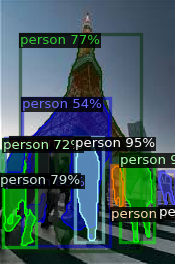

In [ ]:
# Charger l'image (format BGR, comme OpenCV)
img_obj = cv2.imread("image_objects.jpg")

# Prédiction : "outputs" contient boîtes, classes, scores et masques
outputs = predictor(img_obj)

# Visualisation : le Visualizer attend du RGB -> on inverse les canaux avec [:, :, ::-1]
v = Visualizer(img_obj[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

# On ré-inverse en BGR pour cv2_imshow
cv2_imshow(out.get_image()[:, :, ::-1])

In [ ]:
# Liste des objets détectés (réponse à la question 1)
classes = MetadataCatalog.get(cfg.DATASETS.TRAIN[0]).thing_classes   # noms des 80 classes COCO
instances = outputs["instances"].to("cpu")
for c, s in zip(instances.pred_classes.tolist(), instances.scores.tolist()):
    print(f"{classes[c]:<15} score = {s:.2f}")
print("Total objets détectés :", len(instances))

person          score = 0.96
person          score = 0.95
person          score = 0.88
person          score = 0.80
person          score = 0.79
person          score = 0.77
person          score = 0.73
person          score = 0.72
person          score = 0.55
person          score = 0.54
Total objets détectés : 10


In [ ]:
# Question 2 : effet du seuil SCORE_THRESH_TEST
# On recrée un predictor pour chaque seuil et on compte les objets gardés
for seuil in [0.3, 0.5, 0.7, 0.9]:
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = seuil
    pred = DefaultPredictor(cfg)
    inst = pred(img_obj)["instances"]
    print(f"Seuil {seuil} -> {len(inst)} objets détectés")

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # on remet la valeur par défaut

Seuil 0.3 -> 13 objets détectés
Seuil 0.5 -> 10 objets détectés
Seuil 0.7 -> 8 objets détectés
Seuil 0.9 -> 2 objets détectés


### Questions : réponses

**1. Quels objets ont été détectés ?**
Voir la cellule de la liste ci-dessus (à recopier avec les scores). Sur l'exemple du sujet : `person` (scores de 70 % à 100 %) et `tie` (cravate / nœud papillon, ~98-100 %). On voit aussi que le modèle peut **se tromper** : un tigre étiqueté `zebra` (88 %), un chien étiqueté `cat` (59 %), un papillon étiqueté `baseball glove`. C'est normal : le modèle ne connaît que les 80 classes COCO et choisit la plus proche (il n'y a pas de classe « tigre »).

**2. Effet du seuil `SCORE_THRESH_TEST` :**
C'est le score de confiance minimal pour garder une détection.
- **Seuil bas (0.3)** : plus d'objets détectés, mais aussi plus de **faux positifs** (objets inventés, doublons).
- **Seuil haut (0.9)** : seulement les détections très sûres, mais on **rate** des objets (faux négatifs).
- C'est un compromis **précision / rappel**. 0.5 est un bon point de départ.

## Partie 4 : Détection et reconnaissance faciale avec Dlib
### Exercice 4 : Détection faciale
Dlib fournit `get_frontal_face_detector()` : un détecteur de visages **de face** basé sur des descripteurs **HOG** + un classifieur SVM (pas un réseau de neurones profond). Il travaille sur l'image en niveaux de gris.

Visages détectés : 0


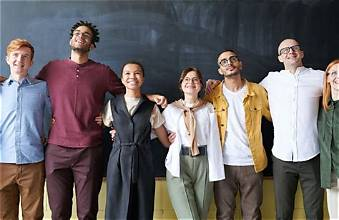

In [ ]:
import dlib

detector = dlib.get_frontal_face_detector()       # détecteur de visages de face (HOG + SVM)

img_people = cv2.imread("people.jpg")
gray_people = cv2.cvtColor(img_people, cv2.COLOR_BGR2GRAY)   # le détecteur travaille en gris

# Renvoie une liste de rectangles (un par visage trouvé)
# detector(gray, 1) agrandirait l'image 1 fois pour trouver de plus petits visages (plus lent)
faces = detector(gray_people)
print("Visages détectés :", len(faces))

for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    # cv2.rectangle(image, coin haut-gauche, coin bas-droit, couleur BGR, épaisseur)
    # (0, 255, 0) = vert en BGR
    cv2.rectangle(img_people, (x, y), (x + w, y + h), (0, 255, 0), 2)

cv2_imshow(img_people)

### Exercice 5 : Reconnaissance faciale
`face_recognition` (construit sur dlib) transforme chaque visage en un **encodage** : un vecteur de **128 nombres** qui résume le visage. Deux photos de la même personne donnent des vecteurs **proches** ; deux personnes différentes donnent des vecteurs **éloignés**. On compare donc la **distance** entre vecteurs (seuil par défaut : 0.6).

In [ ]:
import face_recognition

# Désactiver CUDA pour dlib (comme dans le sujet) : dlib-bin tourne sur CPU
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# load_image_file charge en RGB (contrairement à cv2.imread qui charge en BGR)
image_ref = face_recognition.load_image_file("ref.jpg")
image_test = face_recognition.load_image_file("test.jpg")

# face_encodings renvoie UNE LISTE d'encodages : un par visage trouvé dans l'image
encodages_ref = face_recognition.face_encodings(image_ref)
encodages_test = face_recognition.face_encodings(image_test)
print("Visages dans ref.jpg  :", len(encodages_ref))
print("Visages dans test.jpg :", len(encodages_test))

# Sécurité : si aucun visage trouvé, [0] provoquerait une erreur IndexError
if len(encodages_ref) == 0 or len(encodages_test) == 0:
    print("Aucun visage détecté dans l'une des images")
else:
    encodage_ref = encodages_ref[0]       # on prend le premier visage de la référence
    encodage_test = encodages_test[0]     # ... et le premier visage du test

    # compare_faces renvoie True/False selon la tolérance (0.6 par défaut)
    result = face_recognition.compare_faces([encodage_ref], encodage_test)
    print("Même personne ?", result[0])

    # La distance donne plus d'information qu'un simple True/False (plus petit = plus ressemblant)
    distance = face_recognition.face_distance([encodage_ref], encodage_test)[0]
    print(f"Distance : {distance:.3f} (seuil 0.6)")

Visages dans ref.jpg  : 1
Visages dans test.jpg : 1
Même personne ? True
Distance : 0.490 (seuil 0.6)


In [ ]:
# Question 1 : et si l'image test contient PLUSIEURS visages ?
# On compare la référence à TOUS les visages du test, pas seulement au premier
if len(encodages_ref) > 0:
    distances = face_recognition.face_distance(encodages_test, encodages_ref[0])
    for i, d in enumerate(distances):
        print(f"Visage {i} du test : distance = {d:.3f} -> même personne ? {d <= 0.6}")

### Questions : réponses

**1. Que se passe-t-il si l'image test contient plusieurs visages ?**
`face_encodings()` renvoie une **liste** avec un encodage par visage. Avec `[0]` (comme dans le sujet) on ne compare que le **premier** visage trouvé, qui n'est pas forcément la bonne personne : le résultat peut donc être faux. La bonne méthode est de comparer la référence à **tous** les visages (`face_distance` sur la liste) et de garder le plus proche. Et s'il n'y a **aucun** visage, la liste est vide et `[0]` provoque une erreur : il faut tester `len(...) > 0`.

**2. Quelle précision attendre en conditions réelles (lumière, angles différents) ?**
Les auteurs de `face_recognition` annoncent environ **99,4 %** sur le benchmark LFW, mais ce sont des photos assez propres. En conditions réelles la précision **baisse** :
- faible lumière, contre-jour, ombres ;
- visage de profil ou penché (le modèle est entraîné surtout sur des visages de face) ;
- lunettes, masque, barbe, casquette ; basse résolution ou flou ;
- changement d'âge, d'expression.

On peut ajuster `tolerance` : plus bas = plus strict (moins de faux positifs, plus de faux négatifs). Pour un usage sérieux (présence, sécurité), il faut tester sur ses propres données.

### Exercice 6 : Points caractéristiques du visage (landmarks)
On détecte les **68 points** du visage (modèle dlib `shape_predictor_68`) : contour du menton, sourcils, nez, yeux, bouche.

Visages : 0


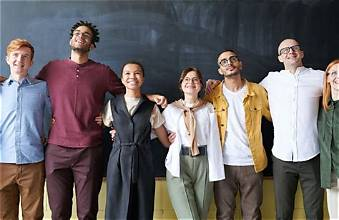

In [ ]:
img_lm = cv2.imread("people.jpg")
rgb = cv2.cvtColor(img_lm, cv2.COLOR_BGR2RGB)     # face_recognition attend du RGB, pas du BGR

# Liste (un dictionnaire par visage) : {nom_de_la_partie: [liste de points (x, y)]}
landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():       # 'chin', 'left_eye', 'nose_tip', 'top_lip'...
        for (x, y) in points:
            cv2.circle(img_lm, (x, y), 2, (0, 0, 255), -1)   # petit disque rouge plein (-1)

cv2_imshow(img_lm)

# Question 1 : quelles parties sont retournées ?
if landmarks_list:
    total = 0
    for partie, points in landmarks_list[0].items():
        print(f"{partie:<14} {len(points)} points")
        total += len(points)
    print("Total :", total, "(les 68 points dlib, certains points de la bouche sont comptés 2 fois)")

In [ ]:
# Question 2 : EAR = Eye Aspect Ratio (rapport d'ouverture de l'oeil)
#
#            ||p2 - p6|| + ||p3 - p5||
#   EAR  =  ---------------------------
#                 2 * ||p1 - p4||
#
# p1 et p4 = coins de l'oeil (largeur) ; p2-p6 et p3-p5 = paupières haut/bas (hauteur)
def ear(oeil):
    p = np.array(oeil, dtype=float)                # 6 points de l'oeil, dans l'ordre dlib
    A = np.linalg.norm(p[1] - p[5])                # hauteur 1
    B = np.linalg.norm(p[2] - p[4])                # hauteur 2
    C = np.linalg.norm(p[0] - p[3])                # largeur
    return (A + B) / (2.0 * C)

for i, lm in enumerate(landmarks_list):
    e_g = ear(lm["left_eye"])
    e_d = ear(lm["right_eye"])
    print(f"Visage {i} : EAR gauche = {e_g:.2f} | EAR droit = {e_d:.2f} | moyenne = {(e_g + e_d) / 2:.2f}")

In [ ]:
# Démonstration de la logique "somnolence" sur une séquence simulée de valeurs d'EAR
def etat_somnolence(ear_values, fps, seuil=0.21, duree_max=2.0):
    """Renvoie True si l'EAR reste sous 'seuil' pendant plus de 'duree_max' secondes d'affilée."""
    images_max = int(duree_max * fps)              # nb d'images consécutives correspondant à 2 s
    compteur = 0
    for e in ear_values:
        compteur = compteur + 1 if e < seuil else 0   # on remet à 0 dès que l'oeil se rouvre
        if compteur >= images_max:
            return True
    return False

fps = 10
clignement = [0.30] * 20 + [0.15] * 2 + [0.30] * 20   # oeil fermé 0,2 s : clignement normal
somnolence = [0.30] * 20 + [0.15] * 30 + [0.30] * 5   # oeil fermé 3 s : alerte
print("Clignement  -> alerte ?", etat_somnolence(clignement, fps))
print("Somnolence  -> alerte ?", etat_somnolence(somnolence, fps))

Clignement  -> alerte ? False
Somnolence  -> alerte ? True


### Questions : réponses

**1. Quelles parties du visage sont retournées par `face_landmarks` ?**
`chin` (menton / mâchoire), `left_eyebrow`, `right_eyebrow`, `nose_bridge` (arête du nez), `nose_tip` (bas du nez), `left_eye`, `right_eye`, `top_lip`, `bottom_lip`. Chaque partie est une liste de points `(x, y)`.

**2. EAR : comment détecter un clignement ou la somnolence d'un conducteur ?**
- Oeil **ouvert** : EAR autour de **0,25 à 0,35** (à ajuster selon la personne). Oeil **fermé** : EAR proche de **0** (en pratique < 0,2).
- **Clignement** : l'EAR chute sous le seuil pendant très peu d'images (~0,1 à 0,4 s) puis remonte.
- **Somnolence** : l'EAR reste sous le seuil pendant **plusieurs images consécutives** (ex : plus de 2 secondes). On compte les images avec un compteur qu'on remet à 0 dès que l'oeil se rouvre, et on déclenche une **alerte sonore** si `compteur >= durée × fps`.
- On fait la **moyenne des deux yeux** pour être plus robuste. Limites : lunettes de soleil, mauvaise lumière, tête tournée.

## Partie 5 : YOLO en temps réel
### Exercice 7 : Comparer Mask R-CNN et YOLO
- **Mask R-CNN** = détecteur **en deux étapes** (d'abord des régions candidates, puis classification + masque) : précis, mais plus lent.
- **YOLO** (*You Only Look Once*) = détecteur **en une seule passe** sur toute l'image : très rapide, adapté au **temps réel**.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

image 1/1 /content/image_objects.jpg: 640x448 3 persons, 7.5ms
Speed: 1.7ms preprocess, 7.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 448)


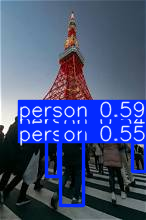

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")        # 'n' = nano : le plus petit et le plus rapide ; téléchargé automatiquement

# Image de test (même logique que le sujet : repli sur people.jpg si besoin)
image_path = "image_objects.jpg"
if not os.path.exists(image_path):
    print(f"'{image_path}' non trouvé. Utilisation de 'people.jpg' à la place.")
    image_path = "people.jpg"

# a) Détection sur l'image ; conf=0.5 = même idée que SCORE_THRESH_TEST
try:
    results = model(image_path, conf=0.5)
    cv2_imshow(results[0].plot())          # plot() dessine boîtes + étiquettes (image BGR)
except Exception as e:
    print("Erreur lors de la détection :", e)

In [ ]:
# Question 1 : comparer les temps d'inférence avec time.time()
img_test = cv2.imread(image_path)

def mesurer(fonction, n=5):
    fonction()                              # 1er appel = "échauffement" (chargement GPU...), pas compté
    debut = time.time()
    for _ in range(n):
        fonction()
    return (time.time() - debut) / n        # temps moyen par image

t_yolo = mesurer(lambda: model(img_test, conf=0.5, verbose=False))

if "predictor" in globals():                # predictor vient de l'exercice 3 (Detectron2)
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
    t_rcnn = mesurer(lambda: predictor(img_test))
    print(f"YOLOv8n   : {t_yolo * 1000:.0f} ms / image")
    print(f"Mask R-CNN : {t_rcnn * 1000:.0f} ms / image")
    print(f"YOLO est environ {t_rcnn / t_yolo:.1f}x plus rapide")
else:
    print(f"YOLOv8n : {t_yolo * 1000:.0f} ms / image (lancer l'exercice 3 pour comparer avec Mask R-CNN)")

YOLOv8n   : 10 ms / image
Mask R-CNN : 132 ms / image
YOLO est environ 13.3x plus rapide


Masques disponibles ? True
Nombre de masques : 2


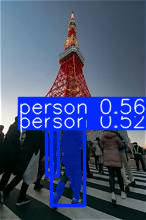

In [ ]:
# Question 2 : YOLO fait-il de la segmentation ? Oui avec la variante "-seg"
model_seg = YOLO("yolov8n-seg.pt")
res_seg = model_seg(image_path, conf=0.5, verbose=False)

print("Masques disponibles ?", res_seg[0].masks is not None)
if res_seg[0].masks is not None:
    print("Nombre de masques :", len(res_seg[0].masks))
cv2_imshow(res_seg[0].plot())

### Questions : réponses

**1. Temps d'inférence :** voir la cellule ci-dessus (à recopier : YOLOv8n ≈ ___ ms, Mask R-CNN ≈ ___ ms). En général YOLOv8n est **nettement plus rapide** (plusieurs fois), surtout sur GPU.

**2. YOLO fournit-il des masques ?** Le modèle de base `yolov8n.pt` donne seulement des **boîtes** + classes + scores. Avec **`yolov8n-seg.pt`** on obtient aussi des **masques de segmentation** (`results[0].masks`), avec une qualité de contours en général un peu moins fine que Mask R-CNN.

**3. Dans quels cas préférer chaque modèle ?**

| | **YOLO** | **Mask R-CNN** |
|---|---|---|
| Vitesse | très rapide, temps réel | plus lent |
| Précision des contours | correcte | très bonne (masques précis) |
| Idéal pour | vidéo, webcam, comptage de personnes, robots, embarqué | analyse d'images fixes, imagerie médicale, mesure de surfaces, découpage précis d'objets |
| Ressources | léger (nano tourne sur petit matériel) | lourd (GPU conseillé) |

## Mini-projet  : Floutage automatique des visages
Détection des visages avec dlib, puis `cv2.GaussianBlur` sur chaque zone pour **anonymiser** (conformité vie privée).

0 visage(s) flouté(s) -> visages_floutes.jpg


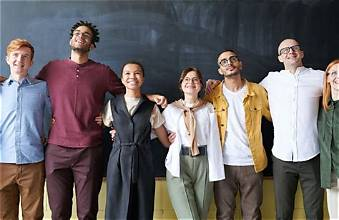

In [ ]:
def flouter_visages(chemin_image, sortie="visages_floutes.jpg"):
    img = cv2.imread(chemin_image)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = dlib.get_frontal_face_detector()(gray)

    for face in faces:
        # On borne les coordonnées pour ne pas sortir de l'image (dlib peut donner des valeurs négatives)
        x1, y1 = max(face.left(), 0), max(face.top(), 0)
        x2, y2 = min(face.right(), img.shape[1]), min(face.bottom(), img.shape[0])

        zone = img[y1:y2, x1:x2]                         # ROI = région d'intérêt (le visage)
        # noyau (99, 99) : grand et impair -> flou fort ; sigma=30 pour bien l'étaler
        img[y1:y2, x1:x2] = cv2.GaussianBlur(zone, (99, 99), 30)   # on remplace le visage par sa version floue

    cv2.imwrite(sortie, img)
    print(f"{len(faces)} visage(s) flouté(s) -> {sortie}")
    return img

cv2_imshow(flouter_visages("people.jpg"))